# 패턴 비교와 선택

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 견줄 조건을 고정하고 패턴마다 다르게 둘 값 둘만 따로 적습니다.
3. 자료에서 질문 셋을 고르고 정답 문서 ID를 함께 봅니다.
4. 패턴 셋을 함수 셋으로 만들어 같은 질문 벌에 차례로 씁니다.
5. 정답 문서의 자리와 서비스 요청 수를 기록 아홉 줄로 모읍니다.
6. 자리를 셀 때 재는 문서 수를 바꿔 보고 기록을 파일 하나로 씁니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 스물두 번이고 임베딩 열여섯 번과 답 모델 여섯 번입니다.
패턴 셋에 질문 셋이라 실행이 아홉 번이고 실행 하나에 요청이 한 번에서 네 번까지 듭니다.
임베딩은 문서 한 번과 실행 아홉 번에서 열다섯 번입니다.

예상 비용은 미화 0.01달러 아래이고 읽어 오는 파일은 문서 파일과 질문 파일 둘입니다.
새로 쓰는 파일은 `runs/pattern-comparison.json` 하나이고 실행 시간은 3분 안팎입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 4절부터 7절까지 읽습니다.
견줄 조건을 고정하고 질문 셋을 고르는 자리입니다.
8절부터 11절까지는 패턴 셋을 함수로 만들어 아홉 번 실행하고 표로 모으는 자리입니다.
12절과 13절은 재는 문서 수를 바꿔 보고 산출 파일을 쓰는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

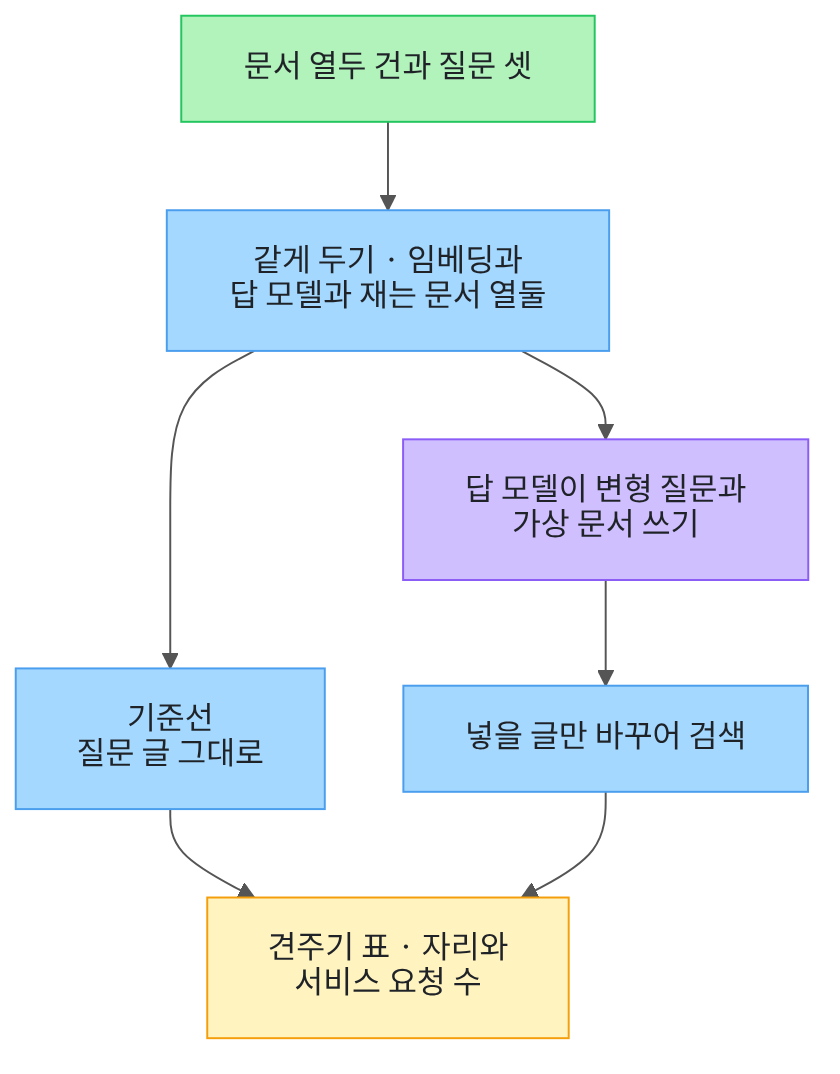

위에서 아래로 읽습니다.
맨 위 초록 상자가 세 패턴에 똑같이 넣는 자료입니다.
그 아래 파란 상자가 패턴 사이에 같게 두는 설정입니다.
보라 상자 하나만 답 모델을 부르는 자리이고 나머지 파란 상자는 코드가 하는 일입니다.
맨 아래 노란 상자가 출력으로 확인한 값 둘입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 여섯 개를 불러옵니다.
앞의 넷은 자료 읽기와 제곱근과 폴더 확인과 지문 만들기에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.
이름 `hashlib`은 Ch 7 08절에서 쓴 것이고 파일 내용이 같은지 견줄 지문을 만듭니다.

In [2]:
# 자료 읽기·제곱근·폴더 확인·지문 만들기와 임베딩·답 모델 이름을 불러옵니다
import hashlib
import json
import math
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model

print("불러온 이름:", "hashlib", "json", "math", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: hashlib json math os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 여섯 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 08절에서 쓴 것과 같습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-19에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~08절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01~08절에서 쓴 코드와 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
01절부터 08절까지 이 파일 둘만 읽었습니다.

절마다 고른 질문과 정답 문서는 달랐습니다.
그래서 앞 절 숫자를 이 절 표로 옮겨 적으면 조건이 맞지 않습니다.
이 절은 질문 셋을 새로 정하고 패턴마다 같은 벌로 다시 잽니다.

## 4. 값 정하기

다음 셀은 01~08절에서 쓰던 값 다섯을 그대로 적는 준비 셀입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.

In [7]:
# 01~08절에서 쓰던 값 셋과 Ch 12 06절 순위 합치기 값 둘을 그대로 적습니다
similarity_top = 1
top_three = 3
top_all = 12
rank_constant = 60
base_weight = 1.0
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("순위 상수:", rank_constant)
print("목록 하나에 줄 가중치:", base_weight)

코사인 유사도의 가장 큰 값: 1
나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
순위 상수: 60
목록 하나에 줄 가중치: 1.0


다음 셀은 이 절이 패턴마다 다르게 두는 값 둘을 적습니다.
변형 질문 수는 02절에서 셋이었고 이 절은 둘로 줄였습니다.
줄인 까닭은 질문 셋을 돌리면 요청이 곱으로 늘기 때문입니다.

In [8]:
# 패턴마다 다르게 두는 값 둘을 적어 둡니다
variant_count = 2
doc_sentences = 2
print("만들 변형 질문 수:", variant_count)
print("가상 문서의 문장 수:", doc_sentences)

만들 변형 질문 수: 2
가상 문서의 문장 수: 2


**결과 읽기** — 출력 줄 `만들 변형 질문 수: 2`가 변형 질문 패턴에 쓸 값입니다.
출력 줄 `가상 문서의 문장 수: 2`가 가상 문서 패턴에 쓸 값입니다.

이 값 둘만 패턴 사이에서 다릅니다.
나머지 설정은 세 패턴에 모두 같게 둡니다.

## 5. 앞 절 부품 준비

다음 여덟 셀은 01~08절에서 이미 읽은 코드입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
문서 글 모으기와 거리 함수 넷과 순위 함수 둘과 자리 세기 둘이 있습니다.
순위 합치기 둘과 줄 다루기 둘과 머리글 둘도 같은 코드로 다시 정의합니다.

In [9]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12 06절과 같은 코드)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


In [10]:
# Ch 12 01절 점곱·길이·코사인 유사도·코사인 거리를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product


def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity

In [11]:
# Ch 12 05절 거리 순위 만들기와 02절 검색 한 번 묶기를 같은 코드로 다시 정의합니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(doc_ids)):
        distance = cosine_distance(question_vector, doc_vectors[i])
        pairs.append((distance, doc_ids[i]))
    hit_list = []
    # sorted(목록)는 튜플의 첫 값인 거리를 작은 값부터 정렬합니다
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]


def search_ids(question):
    question_vector = embedding_model.embed_query(question)
    hit_list = rank_by_distance(question_vector, top_all)
    found_ids = unique_doc_ids(hit_list)
    return found_ids

In [12]:
# Ch 11 01절 문서 ID 모으기와 정답 자리 세기를 같은 코드로 다시 정의합니다
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids


def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

In [13]:
# 순위 목록 여러 개를 받아 문서마다 자리 몫을 더한 합친 점수를 냅니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            doc_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[doc_id] = scores.get(doc_id, 0.0) + share
    return scores

In [14]:
# 합친 점수가 큰 순서로 문서 ID 목록을 만듭니다(Ch 12 04~06절과 같은 음수 붙이기)
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for doc_id in scores:
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[doc_id], doc_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

In [15]:
# 02절 줄 나누기와 05절 줄 이어 붙이기를 같은 코드로 다시 정의합니다
def split_lines(reply_text):
    lines = []
    for line in reply_text.split("\n"):
        clean_line = line.strip()
        if clean_line != "":
            lines.append(clean_line)
    return lines


def join_lines(lines):
    joined_text = ""
    for line in lines:
        if joined_text == "":
            joined_text = line
        else:
            joined_text = joined_text + " " + line
    return joined_text

In [16]:
# 02절 변형 질문 머리글과 05절 가상 문서 머리글을 같은 코드로 다시 정의합니다
def build_variant_prompt(question):
    variant_head = "아래 질문과 같은 것을 묻되 표현과 관점을 달리한 검색 질문을 "
    variant_head = variant_head + str(variant_count) + "줄 적으세요.\n"
    variant_head = variant_head + "한 줄에 질문 하나만 적고 번호나 기호를 붙이지 마세요.\n"
    variant_head = variant_head + "질문이 가리키는 대상과 조건은 그대로 두세요.\n\n"
    prompt_text = variant_head + "질문: " + question
    return prompt_text


def build_hyde_prompt(question):
    hyde_head = "아래 질문에 답할 법한 도서관 안내문을 지어 쓰세요.\n"
    hyde_head = hyde_head + "물음표로 끝나는 질문이 아니라 안내문 문장으로 " + str(doc_sentences) + "문장 적으세요.\n"
    hyde_head = hyde_head + "지어낸 숫자는 넣지 말고 무엇을 어디에서 하는지만 적으세요.\n"
    hyde_head = hyde_head + "번호나 따옴표를 붙이지 마세요.\n\n"
    prompt_text = hyde_head + "질문: " + question
    return prompt_text

준비 셀 여덟 개를 지났습니다.
머리글 둘은 02절과 05절에서 쓴 글자 그대로입니다.
같은 머리글을 써야 두 패턴을 앞 절과 같은 조건으로 견줄 수 있습니다.
06절 보정 검색 함수와 07절 점수 함수와 08절 갈래 함수는 가져오지 않았습니다.

## 6. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [17]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 08절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.

문서 벡터는 한 번만 만들어 세 패턴이 함께 씁니다.
같은 문서 벡터를 써야 자리를 견줄 수 있습니다.

## 7. 견줄 질문 셋 고르기

자료의 질문 여덟 개 가운데 셋을 고릅니다.
갈래가 겹치지 않게 도서와 시설과 계정에서 하나씩 골랐습니다.
정답 문서 ID는 자료에 적혀 있는 것을 그대로 씁니다.

In [18]:
# 견줄 질문 셋을 자료에서 고르고 번호·정답 문서 ID와 함께 봅니다
chosen_qids = ["C02", "C05", "C06"]
question_set = []
for query in queries:
    if query["qid"] in chosen_qids:
        question_set.append(query)
print("견줄 질문 수:", len(question_set))
print("질문 번호 | 정답 문서 ID | 질문")
for item in question_set:
    print(item["qid"], "|", item["gold_doc_id"], "|", item["question"])

견줄 질문 수: 3
질문 번호 | 정답 문서 ID | 질문
C02 | LIB-002 | 책을 늦게 반납하면 돈을 내나요?
C05 | FAC-003 | 토요일 자료실 폐관 시각은?
C06 | ACC-001 | 재설정 URL은 언제까지 쓸 수 있나요?


**결과 읽기** — 출력 줄 `견줄 질문 수: 3`으로 질문 셋을 골랐습니다.
라벨 줄 `질문 번호 | 정답 문서 ID | 질문` 아래 세 줄이 이번에 쓸 질문 벌입니다.
첫 줄은 `C02 | LIB-002`이고 둘째 줄은 `C05 | FAC-003`이며 셋째 줄은 `C06 | ACC-001`입니다.

이 질문 벌과 정답 문서는 세 패턴에 모두 같습니다.
질문 수가 셋뿐이라 한 질문이 뒤집히면 표가 크게 움직입니다.

## 8. 패턴 하나를 함수 하나로

패턴 셋을 함수 셋으로 만듭니다.
세 함수는 모두 질문 글 하나를 받아 같은 모양을 냅니다.
문서 ID 목록 하나와 그 실행에 든 서비스 요청 수 하나입니다.
첫 함수는 기준선이고 질문 글을 그대로 검색합니다.

In [19]:
# 기준선은 질문 글을 그대로 검색합니다(부를 때마다 임베딩 요청 1번)
def run_baseline(question_text):
    found_ids = search_ids(question_text)
    call_count = 1
    return {"문서 ID 목록": found_ids, "서비스 요청 수": call_count}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_baseline`은 질문 글 하나를 그대로 `search_ids`에 넘깁니다.
드는 서비스 요청은 질문을 벡터로 바꾸는 임베딩 한 번뿐입니다.
답 모델은 부르지 않습니다.

다음 셀은 변형 질문 패턴의 앞부분입니다.

In [20]:
# 원 질문과 변형 질문 둘을 검색할 글 목록 하나로 모읍니다(부를 때마다 모델 요청 1번)
def build_search_texts(question_text):
    variant_prompt = build_variant_prompt(question_text)
    reply = model.invoke(variant_prompt)
    variant_lines = split_lines(reply.text)
    search_texts = [question_text]
    for line in variant_lines[:variant_count]:
        search_texts.append(line)
    return search_texts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_search_texts`는 02절 머리글로 변형 질문을 받습니다.
받은 줄에서 앞의 둘만 골라 원 질문 뒤에 붙입니다.
그래서 검색할 글이 원 질문 하나와 변형 질문 둘로 셋이 됩니다.

다음 셀은 그 글 셋으로 검색해 목록을 합칩니다.

In [21]:
# 검색할 글마다 순위 목록을 만들고 순위 합치기로 한 목록에 모읍니다(임베딩 요청 3번)
def run_multi(question_text):
    search_texts = build_search_texts(question_text)
    id_lists = []
    weight_list = []
    for text in search_texts:
        id_lists.append(search_ids(text))
        weight_list.append(base_weight)
    found_ids = fuse_rank(id_lists, weight_list)
    return {"문서 ID 목록": found_ids, "서비스 요청 수": len(id_lists) + 1}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_multi`는 검색할 글마다 문서 ID 목록을 하나씩 만듭니다.
목록 셋을 Ch 12 06절 순위 합치기로 한 목록에 모읍니다.
드는 서비스 요청은 답 모델 한 번과 임베딩 셋을 더해 넷입니다.

다음 셀은 가상 문서 패턴입니다.

In [22]:
# 가상 문서를 지어 받아 그 글로 검색합니다(모델 요청 1번·임베딩 요청 1번)
def run_hyde(question_text):
    hyde_prompt = build_hyde_prompt(question_text)
    reply = model.invoke(hyde_prompt)
    hyde_lines = split_lines(reply.text)
    hyde_text = join_lines(hyde_lines)
    found_ids = search_ids(hyde_text)
    call_count = 2
    return {"문서 ID 목록": found_ids, "서비스 요청 수": call_count}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_hyde`는 05절 머리글로 안내문 두 문장을 받습니다.
받은 줄을 한 글로 이어 붙여 그 글로 검색합니다.
드는 서비스 요청은 답 모델 한 번과 임베딩 한 번을 더해 둘입니다.

## 9. 기록 한 줄 만들기

실행 하나를 기록 한 줄로 만듭니다.
이 절의 기록 한 줄은 산출 파일에 그대로 담깁니다.
그래서 칸 이름을 Ch 12 실행 기록 파일처럼 영어로 적었습니다.

In [23]:
# 실행 한 번을 기록 한 줄로 만듭니다(산출 파일에 그대로 담을 칸 일곱입니다)
def run_row(pattern_name, item, result):
    found_ids = result["문서 ID 목록"]
    row = {"pattern": pattern_name, "qid": item["qid"]}
    row["question"] = item["question"]
    row["gold_doc_id"] = item["gold_doc_id"]
    row["found_ids"] = found_ids
    row["rank"] = find_gold_rank(found_ids, [item["gold_doc_id"]])
    row["service_calls"] = result["서비스 요청 수"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 패턴 이름과 질문 번호와 질문 글과 정답 문서 ID입니다.
거기에 찾은 문서 ID 목록과 정답 문서의 자리와 서비스 요청 수를 더해 일곱입니다.
자리는 문서 열두 건을 모두 재고 센 값이라 1부터 12까지 나옵니다.

## 10. 아홉 실행 돌리기

질문 셋을 세 패턴에 차례로 넣습니다.
실행이 아홉 번이고 이 셀에서 서비스 요청이 스물한 번 갑니다.
질문 하나를 세 패턴으로 이어서 실행해 표에서 나란히 읽히게 했습니다.

In [24]:
# 질문 셋을 세 패턴으로 차례로 돌려 기록 아홉 줄을 만듭니다(서비스 요청 21번)
run_rows = []
for item in question_set:
    base_result = run_baseline(item["question"])
    run_rows.append(run_row("기준선", item, base_result))
    multi_result = run_multi(item["question"])
    run_rows.append(run_row("변형 질문", item, multi_result))
    hyde_result = run_hyde(item["question"])
    run_rows.append(run_row("가상 문서", item, hyde_result))
print("기록 줄 수:", len(run_rows))

기록 줄 수: 9


**결과 읽기** — 출력 줄 `기록 줄 수: 9`로 실행 아홉 번을 모두 담았습니다.

이 셀은 답 모델을 여섯 번 부르므로 몇십 초가 걸립니다.
모델이 쓴 변형 질문과 가상 문서는 실행마다 문장이 달라질 수 있습니다.

## 11. 견주기 표 보기

기록 아홉 줄을 한 표로 봅니다.
서비스 요청 수도 함께 더해 미리 적어 둔 값과 견줍니다.

In [25]:
# 기록 아홉 줄을 출력하고 서비스 요청 수를 모두 더해 미리 적어 둔 값과 견줍니다
planned_calls = 21
counted_calls = 0
print("패턴 | 질문 번호 | 정답 문서의 자리 | 서비스 요청 수")
for row in run_rows:
    print(row["pattern"], "|", row["qid"], "|", row["rank"], "|", row["service_calls"])
    counted_calls = counted_calls + row["service_calls"]
print("미리 적어 둔 서비스 요청 수:", planned_calls)
print("실제로 센 서비스 요청 수:", counted_calls)
assert counted_calls == planned_calls, "센 요청 수가 미리 적어 둔 값과 다릅니다."

패턴 | 질문 번호 | 정답 문서의 자리 | 서비스 요청 수
기준선 | C02 | 7 | 1
변형 질문 | C02 | 4 | 4
가상 문서 | C02 | 1 | 2
기준선 | C05 | 1 | 1
변형 질문 | C05 | 1 | 4
가상 문서 | C05 | 1 | 2
기준선 | C06 | 1 | 1
변형 질문 | C06 | 1 | 4
가상 문서 | C06 | 1 | 2
미리 적어 둔 서비스 요청 수: 21
실제로 센 서비스 요청 수: 21


**결과 읽기** — 라벨 줄 아래 첫 줄이 `기준선 | C02 | 7 | 1`입니다.
넷째 줄은 `기준선 | C05 | 1 | 1`이고 일곱째 줄은 `기준선 | C06 | 1 | 1`입니다.
출력 줄 `실제로 센 서비스 요청 수: 21`이 미리 적어 둔 값과 같습니다.
요청 수 칸은 기준선 하나와 변형 질문 넷과 가상 문서 둘입니다.

패턴을 얹은 여섯 줄의 자리는 새 커널 네 번 실행에서 셋이 서로 달라졌습니다.
모델이 쓴 변형 질문과 가상 문서가 실행마다 달라지기 때문입니다.
그래서 갈린 칸은 이 절의 결론과 그림 라벨에 넣지 않았습니다.
`assert` 한 줄은 요청 수만 보고 모델이 쓴 글에는 걸지 않았습니다.

## 12. 값 바꿔 보기 · 재는 문서 수를 셋으로

바꿀 것은 자리를 셀 때 재는 문서 수 하나입니다.
같은 기록 아홉 줄을 그대로 두고 앞 세 자리만 봅니다.
서비스 요청은 늘지 않습니다.
실행 전에 예상해 봅니다. 자리가 셋보다 뒤였던 줄은 영이 됩니다.

In [26]:
# 자리를 셀 때 재는 문서 수를 열둘에서 셋으로 바꿔 같은 기록을 다시 셉니다
print("패턴 | 질문 번호 | 열둘에서 센 자리 | 앞 세 자리에서 센 자리")
for row in run_rows:
    short_ids = row["found_ids"][:top_three]
    short_place = find_gold_rank(short_ids, [row["gold_doc_id"]])
    print(row["pattern"], "|", row["qid"], "|", row["rank"], "|", short_place)

패턴 | 질문 번호 | 열둘에서 센 자리 | 앞 세 자리에서 센 자리
기준선 | C02 | 7 | 0
변형 질문 | C02 | 4 | 0
가상 문서 | C02 | 1 | 1
기준선 | C05 | 1 | 1
변형 질문 | C05 | 1 | 1
가상 문서 | C05 | 1 | 1
기준선 | C06 | 1 | 1
변형 질문 | C06 | 1 | 1
가상 문서 | C06 | 1 | 1


**결과 읽기** — 라벨 줄 `패턴 | 질문 번호 | 열둘에서 센 자리 | 앞 세 자리에서 센 자리`가 보입니다.
첫 줄은 `기준선 | C02 | 7 | 0`이고 영은 앞 세 자리 안에 없었다는 뜻입니다.
넷째 줄은 `기준선 | C05 | 1 | 1`로 두 칸이 같습니다.

자리가 셋보다 뒤였던 줄은 모두 영이 됩니다.
서로 달랐던 값이 같아 보여 패턴을 가르기 어려워집니다.
그래서 이 절은 문서 열두 건을 모두 재어 자리를 셌습니다.

## 13. 산출 파일 쓰기

이 챕터에서 파일을 쓰는 절은 이 절 하나입니다.
먼저 문서 파일과 질문 파일의 지문을 만듭니다.
지문은 파일 내용이 같은지 나중에 견주려고 담는 값입니다.

In [27]:
# 문서 파일과 질문 파일의 지문을 만들고 산출 파일에 담을 칸 이름을 적어 둡니다
with open(data_path + "/documents.json", "rb") as file:
    document_hash = hashlib.sha256(file.read()).hexdigest()
with open(data_path + "/queries.json", "rb") as file:
    query_hash = hashlib.sha256(file.read()).hexdigest()
expected_columns = ["pattern", "qid", "question", "gold_doc_id", "found_ids", "rank", "service_calls"]
print("문서 지문 글자 수:", len(document_hash))
print("질문 지문 글자 수:", len(query_hash))
print("담을 칸 이름 수:", len(expected_columns))

문서 지문 글자 수: 64
질문 지문 글자 수: 64
담을 칸 이름 수: 7


**결과 읽기** — 출력 줄 `문서 지문 글자 수: 64`로 지문 하나가 예순네 글자입니다.
출력 줄 `담을 칸 이름 수: 7`이 기록 한 줄의 칸 수와 같습니다.

지문 값 자체는 길어서 출력하지 않습니다.
담는 것은 지문 둘과 모델 이름과 벡터의 숫자 개수 설정입니다.

다음 셀은 설정 칸과 기록 아홉 줄을 파일 하나로 씁니다.

In [28]:
# 설정 칸 다섯과 기록 아홉 줄을 담아 산출 파일 하나를 새로 씁니다
runs_path = root_path + "/labs/part4/ch14-rag-patterns/runs"
log = {"chat_model": model.model_name, "embedding_model": embedding_model_name}
log["embedding_dimensions"] = vector_dimensions
log["document_hash"] = document_hash
log["query_hash"] = query_hash
log["rows"] = run_rows
with open(runs_path + "/pattern-comparison.json", "w", encoding="utf-8") as file:
    file.write(json.dumps(log, ensure_ascii=False, indent=2))
print("쓴 파일 이름:", "pattern-comparison.json")
print("담은 줄 수:", len(log["rows"]))

쓴 파일 이름: pattern-comparison.json
담은 줄 수: 9


**결과 읽기** — 출력 줄 `쓴 파일 이름: pattern-comparison.json`이 새로 쓴 파일입니다.
출력 줄 `담은 줄 수: 9`로 기록 아홉 줄을 모두 담았습니다.

파일은 실습 폴더의 `runs` 폴더에 들어갑니다.
이 파일은 학생 묶음에 함께 들어가는 파일입니다.

다음 셀은 쓴 파일을 다시 읽어 확인합니다.

In [29]:
# 쓴 파일을 다시 읽어 줄 수와 줄의 칸 이름을 확인합니다
with open(runs_path + "/pattern-comparison.json", encoding="utf-8") as file:
    saved = json.loads(file.read())
saved_rows = saved["rows"]
column_names = []
for name in saved_rows[0]:
    column_names.append(name)
print("다시 읽은 줄 수:", len(saved_rows))
print("줄의 칸 이름:", column_names)
assert len(saved_rows) == len(run_rows), "다시 읽은 줄 수가 쓴 줄 수와 다릅니다."
assert column_names == expected_columns, "다시 읽은 칸 이름이 적어 둔 이름과 다릅니다."

다시 읽은 줄 수: 9
줄의 칸 이름: ['pattern', 'qid', 'question', 'gold_doc_id', 'found_ids', 'rank', 'service_calls']


**결과 읽기** — 출력 줄 `다시 읽은 줄 수: 9`가 쓴 줄 수와 같습니다.
라벨 줄 `줄의 칸 이름` 뒤에 칸 이름 일곱이 차례로 보입니다.

`assert` 두 줄은 줄 수와 칸 이름만 봅니다.
파일 안의 자리 값과 모델이 쓴 글에는 `assert`를 걸지 않았습니다.

## 정리

1. 문서와 질문과 정답과 모델과 재는 문서 수를 고정하고 패턴 셋만 바꿔 아홉 번 실행했습니다.
2. 기준선은 질문 셋 가운데 둘에서 정답 문서를 첫 자리에 두었습니다.
3. 이미 첫 자리인 질문에서는 패턴을 얹어도 자리가 앞으로 갈 수 없고 요청만 늘었습니다.
4. 모델이 글을 쓰는 두 패턴은 같은 코드에서도 자리가 실행마다 달라졌습니다.
5. 그래서 이 질문 벌에서는 어느 패턴이 낫다고 적지 않고 기록 아홉 줄을 파일 하나로 썼습니다.

이 챕터의 마지막에는 실습 절이 붙습니다.
그 절은 이 챕터에서 쓴 이름과 함수만으로 작은 상황 하나를 함께 따라 실행합니다.